Usar VGG O YoloV8 (MEJOR) disponible para segmentar los elementos detectados en una imagen.

Verificar fotografias de mascotas, de personas, elementos de vestir (mejor algo relacionado a el larping o videojuegos)...

El usuario carga la imagen y el algoritmo retorna la imagen segmentada

# Segmentación de objetos con YOLOv8

En este ejercicio se utiliza **YOLOv8-seg**, un modelo preentrenado que detecta objetos y devuelve una máscara para cada instancia encontrada. La imagen de entrada puede contener mascotas, personas, ropa, accesorios u objetos relacionados con videojuegos.

El modelo utilizado fue entrenado con COCO, por lo que solo reconocerá las clases incluidas en ese conjunto. La imagen segmentada se guardará en la carpeta `resultados_segmentacion/`.

In [1]:
# Ejecuta esta celda una sola vez si ultralytics no está instalado.
%pip install -q ultralytics

Note: you may need to restart the kernel to use updated packages.


Imagen cargada: dataset_genero\val\souls\souls_02.png
Resolución: (620, 1200)


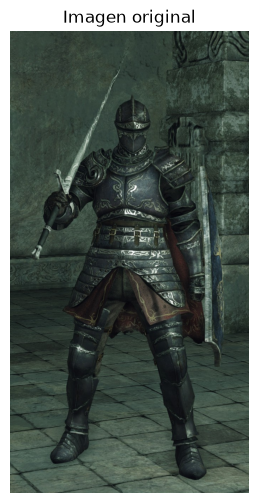

In [7]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
from ultralytics import YOLO

# Imagen usada para probar la segmentación.
IMAGE_DIR = Path("dataset_genero")
IMAGE_PATH = IMAGE_DIR / "val" / "souls" / "souls_02.png"
OUTPUT_DIR = Path("resultados_segmentacion")
OUTPUT_DIR.mkdir(exist_ok=True)

valid_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
if not IMAGE_PATH.exists():
    available_images = sorted(
        path for path in IMAGE_DIR.rglob("*")
        if path.is_file() and path.suffix.lower() in valid_extensions
    )
    if available_images:
        IMAGE_PATH = available_images[0]
        print(f"No se encontró la imagen configurada; se usará: {IMAGE_PATH}")
    else:
        raise FileNotFoundError(
            f"No hay imágenes en {IMAGE_DIR}. Agrega una imagen JPG o PNG al dataset."
        )

image = Image.open(IMAGE_PATH).convert("RGB")
print(f"Imagen cargada: {IMAGE_PATH}")
print(f"Resolución: {image.size}")

plt.figure(figsize=(10, 6))
plt.imshow(image)
plt.axis("off")
plt.title("Imagen original")
plt.show()

In [4]:
# La primera ejecución descarga automáticamente los pesos del modelo.
# Después de esa descarga, el modelo queda guardado en la caché local.
model = YOLO("yolov8n-seg.pt")

torch = __import__("torch")
device = 0 if torch.cuda.is_available() else "cpu"
print("Dispositivo usado:", "GPU" if device == 0 else "CPU")

results = model.predict(
    source=str(IMAGE_PATH),
    conf=0.25,
    imgsz=512,
    device=device,
    verbose=False,
)

result = results[0]
print(f"Objetos detectados: {len(result.boxes)}")

Dispositivo usado: CPU
Objetos detectados: 2


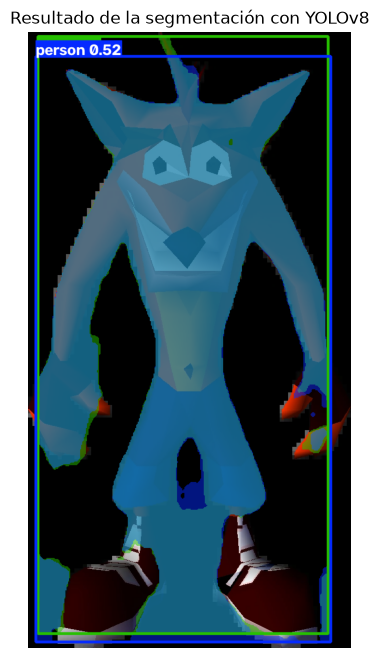

Resultado guardado en: C:\Users\peral\OneDrive\Documentos\Universidad - EAFIT\Semestre V\Inteligencia Artificial\Tareas\ia-2026-2-actividades-JOANPERALTA\semana-11\resultados_segmentacion\no_souls_01_segmentada.jpg


In [5]:
# result.plot() dibuja cajas, etiquetas y las máscaras de segmentación.
segmented_image = result.plot()
output_path = OUTPUT_DIR / f"{IMAGE_PATH.stem}_segmentada.jpg"
Image.fromarray(segmented_image[:, :, ::-1]).save(output_path)

plt.figure(figsize=(12, 8))
plt.imshow(segmented_image[:, :, ::-1])
plt.axis("off")
plt.title("Resultado de la segmentación con YOLOv8")
plt.show()

print(f"Resultado guardado en: {output_path.resolve()}")

## Fine-tuning para mejorar la segmentación

El modelo preentrenado ya reconoce objetos generales, pero para mejorar la segmentación en capturas de videojuegos se necesitan **máscaras anotadas manualmente**. Las imágenes solas no son suficientes: cada objeto debe tener un polígono que indique exactamente qué píxeles pertenecen a él.

Para distinguir un juego tipo Souls de uno que no lo es, se necesita además un clasificador separado. YOLOv8-seg debe entrenarse con clases de objetos como `personaje`, `espada` o `escudo`; `souls` y `no_souls` describen el juego, no una máscara de objeto.

### Estructura necesaria del dataset anotado

Usa una herramienta como CVAT, Roboflow o Label Studio para dibujar los polígonos. Exporta en formato **YOLO Segmentation** con esta estructura:

```text
dataset_souls_seg/
├── images/
│   ├── train/
│   └── val/
├── labels/
│   ├── train/
│   └── val/
└── data.yaml
```

Cada imagen debe tener un `.txt` con el mismo nombre. Cada línea del `.txt` sigue el formato `clase x1 y1 x2 y2 ...`, usando coordenadas normalizadas entre 0 y 1. Recomendación inicial: 100-300 imágenes variadas y al menos 30 por clase de objeto.

In [ ]:
# Actívalo solo cuando dataset_souls_seg/data.yaml exista y tenga máscaras válidas.
RUN_FINE_TUNING = False
DATASET_YAML = Path("dataset_souls_seg/data.yaml")

if RUN_FINE_TUNING:
    if not DATASET_YAML.exists():
        raise FileNotFoundError(
            f"No se encontró {DATASET_YAML}. Exporta primero las anotaciones en formato YOLO Segmentation."
        )

    fine_tuned_model = YOLO("yolov8n-seg.pt")
    training_results = fine_tuned_model.train(
        data=str(DATASET_YAML),
        epochs=30,
        imgsz=512,
        batch=4,
        patience=8,
        device=device,
        project="resultados_segmentacion",
        name="fine_tuning_souls",
        pretrained=True,
        plots=True,
    )
    print("Entrenamiento terminado. Revisa resultados_segmentacion/fine_tuning_souls.")
else:
    print("Fine-tuning desactivado. Cambia RUN_FINE_TUNING a True cuando el dataset esté listo.")

Ejemplo de `data.yaml` para objetos de videojuegos:

```yaml
path: dataset_souls_seg
train: images/train
val: images/val
names:
  0: personaje
  1: espada
  2: escudo
  3: casco
```

Las clases deben coincidir exactamente con las etiquetas usadas al dibujar las máscaras.

In [ ]:
# Inferencia con los pesos ajustados, después de activar y finalizar el entrenamiento.
RUN_CUSTOM_INFERENCE = False
BEST_MODEL = Path("resultados_segmentacion/fine_tuning_souls/weights/best.pt")

if RUN_CUSTOM_INFERENCE:
    if not BEST_MODEL.exists():
        raise FileNotFoundError(f"No se encontró el modelo ajustado: {BEST_MODEL}")
    custom_model = YOLO(str(BEST_MODEL))
    custom_result = custom_model.predict(
        source=str(IMAGE_PATH),
        conf=0.25,
        imgsz=512,
        device=device,
        verbose=False,
    )[0]
    custom_image = custom_result.plot()
    custom_output = OUTPUT_DIR / f"{IMAGE_PATH.stem}_fine_tuned.jpg"
    Image.fromarray(custom_image[:, :, ::-1]).save(custom_output)
    plt.figure(figsize=(12, 8))
    plt.imshow(custom_image[:, :, ::-1])
    plt.axis("off")
    plt.title("Segmentación después del fine-tuning")
    plt.show()
    print(f"Resultado ajustado guardado en: {custom_output.resolve()}")
else:
    print("Inferencia con pesos ajustados desactivada.")

## ¿Por qué tarda tanto?

- `%pip install ultralytics` puede tardar porque descarga paquetes y dependencias. Ejecútalo solo una vez.
- `YOLO("yolov8n-seg.pt")` descarga los pesos aproximadamente la primera vez; después se reutilizan desde la caché.
- La CPU es mucho más lenta que una GPU para redes convolucionales. El código ahora detecta automáticamente si hay CUDA disponible.
- La segmentación calcula máscaras, por lo que tarda más que una clasificación simple.
- El fine-tuning tarda mucho más porque procesa muchas imágenes durante varias épocas.

Para acelerar sin perder demasiado detalle se usa `imgsz=512`, `batch=4` y `yolov8n-seg.pt`. Para una entrega rápida, deja `RUN_FINE_TUNING = False`; actívalo únicamente después de preparar las imágenes y máscaras.

In [6]:
# Resumen de las detecciones para interpretar el resultado.
detections = []
for index, (box, confidence, class_id) in enumerate(
    zip(result.boxes.xyxy.cpu().numpy(), result.boxes.conf.cpu().numpy(), result.boxes.cls.cpu().numpy()),
    start=1,
):
    detections.append({
        "objeto": index,
        "clase": result.names[int(class_id)],
        "confianza": round(float(confidence), 3),
        "x1": round(float(box[0]), 1),
        "y1": round(float(box[1]), 1),
        "x2": round(float(box[2]), 1),
        "y2": round(float(box[3]), 1),
    })

detections_df = pd.DataFrame(detections)
if detections_df.empty:
    print("No se detectaron objetos con confianza >= 0.25.")
else:
    display(detections_df)
    print("Clases detectadas:", ", ".join(detections_df["clase"].tolist()))

,objeto,clase,confianza,x1,y1,x2,y2
0,1,person,0.522,14.4,46.4,577.6,1164.3
1,2,kite,0.255,18.8,8.9,572.7,1148.7


Clases detectadas: person, kite


## Análisis del resultado

Describe qué objetos fueron detectados, cuáles no fueron reconocidos y si las máscaras cubren correctamente cada objeto. Considera la iluminación, el fondo, el tamaño del objeto y las oclusiones.

- **Imagen utilizada:** ` [completar] `
- **Objetos detectados:** ` [completar] `
- **Objetos no detectados o mal segmentados:** ` [completar] `
- **Calidad de las máscaras:** ` [completar] `
- **Limitación del modelo:** YOLOv8n-seg solo reconoce las clases con las que fue entrenado; para clases personalizadas se necesitaría un dataset etiquetado y fine-tuning.

## Clasificación: ¿Souls o no Souls?

La segmentación anterior identifica objetos, pero no el género del videojuego. Para responder esta pregunta se entrena un **clasificador independiente** con dos clases: `souls` y `no_souls`.

Organiza las imágenes así. No uses los nombres de archivo como etiquetas: la carpeta debe representar la etiqueta real.

```text
dataset_genero/
├── train/
│   ├── souls/
│   └── no_souls/
└── val/
    ├── souls/
    └── no_souls/
```

Usa idealmente 50-100 imágenes por clase, tomadas de juegos distintos y con variedad de escenas. Con solo dos imágenes por clase el modelo puede memorizar y no generalizar.

In [ ]:
GENRE_DATASET = Path("dataset_genero")
RUN_GENRE_TRAINING = False
GENRE_MODEL_DIR = Path("resultados_segmentacion/genero_souls")

required_dirs = [
    GENRE_DATASET / "train" / "souls",
    GENRE_DATASET / "train" / "no_souls",
    GENRE_DATASET / "val" / "souls",
    GENRE_DATASET / "val" / "no_souls",
]

if RUN_GENRE_TRAINING:
    missing_dirs = [directory for directory in required_dirs if not directory.exists()]
    if missing_dirs:
        raise FileNotFoundError(
            "Faltan carpetas del dataset: " + ", ".join(str(directory) for directory in missing_dirs)
        )

    genre_model = YOLO("yolov8n-cls.pt")
    genre_model.train(
        data=str(GENRE_DATASET),
        epochs=25,
        imgsz=224,
        batch=8,
        patience=6,
        device=device,
        project="resultados_segmentacion",
        name="genero_souls",
        pretrained=True,
        plots=True,
    )
    print("Clasificador entrenado. Pesos: resultados_segmentacion/genero_souls/weights/best.pt")
else:
    print("Entrenamiento de género desactivado. Prepara dataset_genero y cambia RUN_GENRE_TRAINING a True.")

In [ ]:
RUN_GENRE_PREDICTION = False
GENRE_BEST_MODEL = Path("resultados_segmentacion/genero_souls/weights/best.pt")
NEW_IMAGE_PATH = IMAGE_PATH

if RUN_GENRE_PREDICTION:
    if not GENRE_BEST_MODEL.exists():
        raise FileNotFoundError(
            f"No existe {GENRE_BEST_MODEL}. Ejecuta primero el entrenamiento del clasificador."
        )
    genre_model = YOLO(str(GENRE_BEST_MODEL))
    genre_result = genre_model.predict(
        source=str(NEW_IMAGE_PATH),
        imgsz=224,
        device=device,
        verbose=False,
    )[0]
    probabilities = genre_result.probs.data.cpu().numpy()
    predicted_index = int(probabilities.argmax())
    predicted_label = genre_result.names[predicted_index]
    confidence = float(probabilities[predicted_index])

    print(f"Predicción: {predicted_label}")
    print(f"Confianza: {confidence:.2%}")
    if confidence < 0.70:
        print("Advertencia: confianza baja; agrega más imágenes variadas y revisa las etiquetas.")
else:
    print("Predicción de género desactivada. Cambia RUN_GENRE_PREDICTION a True cuando exista best.pt.")